# Week 7: Neural Networks and Deep Learning

## From one weighted calculation to a trained neural network

This notebook is designed for **Google Colab** and standard Jupyter environments. It is self-contained: the datasets and diagrams used in the lesson are created inside the notebook, so no external downloads are required.

The purpose is not to turn neural networks into a collection of library commands. The purpose is to understand what the network is calculating, what changes during training, and how to judge whether the resulting model generalises.

### By the end of the notebook you should be able to

1. explain why neural networks can be useful for nonlinear relationships;
2. explain what an artificial neuron calculates;
3. describe the roles of inputs, weights and bias;
4. calculate the output of a simple neuron;
5. explain why activation functions are required;
6. describe ReLU and sigmoid at introductory level;
7. distinguish input, hidden and output layers;
8. explain forward propagation;
9. distinguish prediction from learning;
10. explain what loss represents;
11. describe the training loop: forward pass, loss, backpropagation and parameter update;
12. explain the purposes of the optimiser, learning rate, epochs and mini-batches;
13. interpret simple learning curves and recognise possible overfitting;
14. distinguish training, validation and test data;
15. explain what makes deep learning "deep";
16. train, inspect and compare a small multilayer perceptron.

**Working pattern:** read -> predict -> run -> inspect -> explain.

## 0. Setup

The notebook uses NumPy, pandas, Matplotlib and scikit-learn. These packages are already available in standard Google Colab, so there is no installation step.

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

print("Setup complete.")
print("NumPy:", np.__version__)

# Part A: Neural networks are still machine learning

## 1. Start from the machine-learning story

A neural network is still a model trained from examples. The familiar supervised-learning story remains:

**training examples -> model -> prediction -> error -> improvement**

What changes is the model in the middle. A neural network contains layers of small mathematical units connected by learned parameters.

The two most important learned parameter types in this notebook are **weights** and **biases**.

In [ ]:
from matplotlib.patches import FancyBboxPatch

plt.figure(figsize=(11, 3))
ax = plt.gca()
ax.set_xlim(0, 11)
ax.set_ylim(0, 3)
ax.axis("off")

labels = [(0.4, "Training data"), (3.0, "Neural network"), (5.9, "Prediction"), (8.2, "Loss / error"), (10.1, "Improve")]
for x, label in labels:
    box = FancyBboxPatch((x, 1.05), 1.45, 0.75, boxstyle="round,pad=0.05", fill=False)
    ax.add_patch(box)
    ax.text(x + 0.725, 1.425, label, ha="center", va="center", fontsize=10)
for x1, x2 in [(1.85,3.0),(4.45,5.9),(7.35,8.2),(9.65,10.1)]:
    ax.annotate("", xy=(x2,1.425), xytext=(x1,1.425), arrowprops=dict(arrowstyle="->"))
ax.text(3.72, 0.55, "learned weights and biases", ha="center", fontsize=10)
plt.title("Neural networks fit inside the usual supervised-learning workflow")
plt.show()

### Think

A neural network may contain thousands or millions of parameters, but the basic training question remains simple:

> Which parameter changes make the predictions less wrong on the training examples?

# Part B: Why neural networks?

## 2. A pattern that is not well described by one straight boundary

We will create a small two-feature dataset. The class pattern bends around itself, so it provides a useful demonstration of **nonlinearity**.

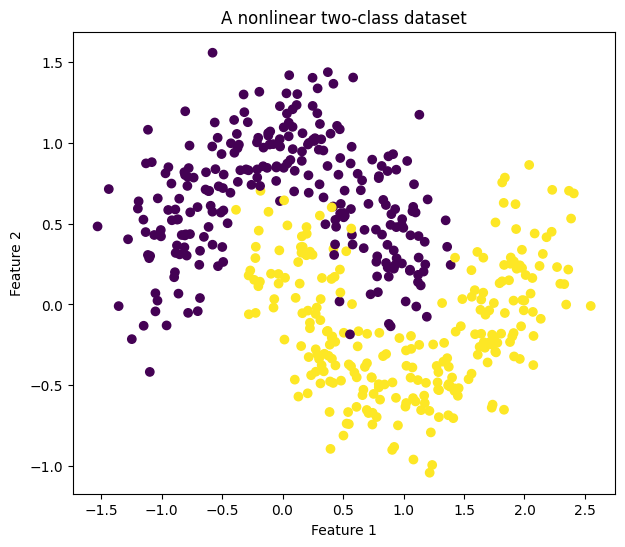

In [ ]:
X_demo, y_demo = make_moons(n_samples=500, noise=0.22, random_state=RANDOM_STATE)

plt.figure(figsize=(7, 6))
plt.scatter(X_demo[:, 0], X_demo[:, 1], c=y_demo)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("A nonlinear two-class dataset")
plt.show()

A linear classifier tries to separate classes using a straight decision boundary. A neural network with nonlinear activation can construct a more flexible boundary.

We will compare the two models on the same train/test split.

In [ ]:
X_train_demo, X_test_demo, y_train_demo, y_test_demo = train_test_split(
    X_demo, y_demo, test_size=0.25, random_state=RANDOM_STATE, stratify=y_demo
)

scaler_demo = StandardScaler()
X_train_demo_s = scaler_demo.fit_transform(X_train_demo)
X_test_demo_s = scaler_demo.transform(X_test_demo)

linear_demo = LogisticRegression(random_state=RANDOM_STATE)
linear_demo.fit(X_train_demo_s, y_train_demo)

mlp_demo = MLPClassifier(
    hidden_layer_sizes=(16,),
    activation="relu",
    learning_rate_init=0.01,
    max_iter=600,
    random_state=RANDOM_STATE
)
mlp_demo.fit(X_train_demo_s, y_train_demo)

print("Logistic regression test accuracy:", round(linear_demo.score(X_test_demo_s, y_test_demo), 3))
print("MLP test accuracy:", round(mlp_demo.score(X_test_demo_s, y_test_demo), 3))

Logistic regression test accuracy: 0.856
MLP test accuracy: 0.976


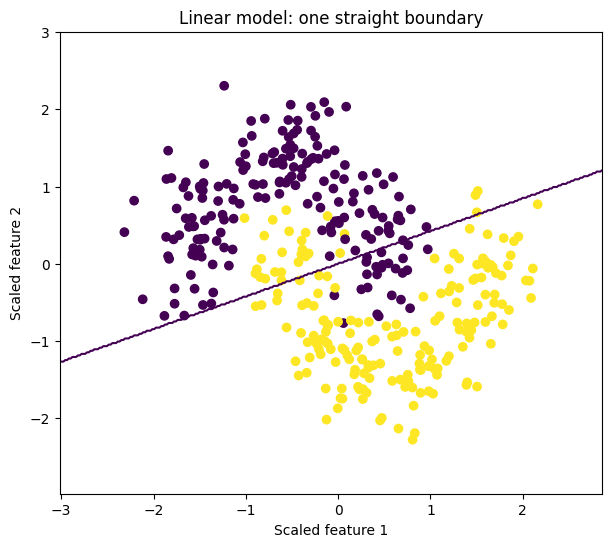

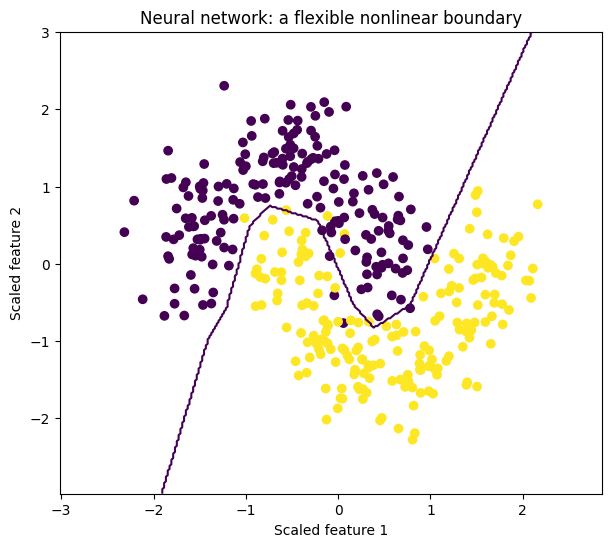

In [ ]:
def plot_decision_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 0.7, X[:, 0].max() + 0.7
    y_min, y_max = X[:, 1].min() - 0.7, X[:, 1].max() + 0.7
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(7, 6))
    plt.contour(xx, yy, zz, levels=[0.5])
    plt.scatter(X[:, 0], X[:, 1], c=y)
    plt.xlabel("Scaled feature 1")
    plt.ylabel("Scaled feature 2")
    plt.title(title)
    plt.show()

plot_decision_boundary(linear_demo, X_train_demo_s, y_train_demo, "Linear model: one straight boundary")
plot_decision_boundary(mlp_demo, X_train_demo_s, y_train_demo, "Neural network: a flexible nonlinear boundary")

### Interpretation

The neural network can represent a more flexible relationship between the inputs and the output. That flexibility is useful when the real pattern is nonlinear.

However, **more flexible does not automatically mean better**. A flexible model can also learn training-specific noise. We will return to this when we study overfitting.

# Part C: One artificial neuron

## 3. Inputs are numerical features

Consider a simple student example:

- $x_1$: study hours;
- $x_2$: attendance;
- $x_3$: assignment score.

A neuron receives these values as evidence and combines them mathematically before producing an output.

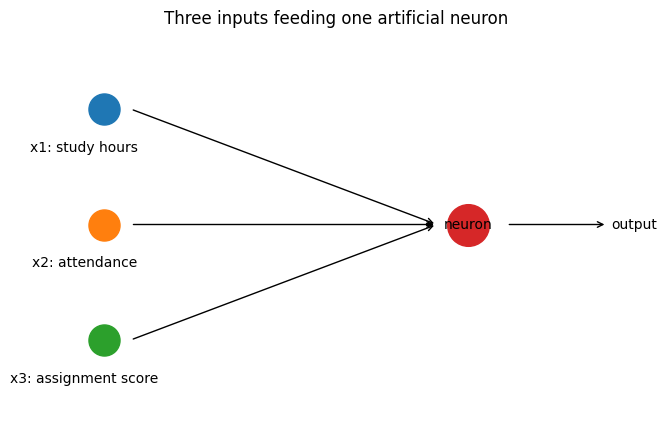

In [ ]:
plt.figure(figsize=(8, 5))
ax = plt.gca()
ax.axis("off")
ax.set_xlim(0, 8)
ax.set_ylim(0, 5)

input_y = [4, 2.5, 1]
input_labels = ["x1: study hours", "x2: attendance", "x3: assignment score"]
for y, label in zip(input_y, input_labels):
    ax.scatter([1], [y], s=500)
    ax.text(0.75, y - 0.55, label, ha="center", fontsize=10)
    ax.annotate("", xy=(5.3, 2.5), xytext=(1.35, y), arrowprops=dict(arrowstyle="->"))
ax.scatter([5.7], [2.5], s=900)
ax.text(5.7, 2.5, "neuron", ha="center", va="center")
ax.annotate("", xy=(7.5, 2.5), xytext=(6.2, 2.5), arrowprops=dict(arrowstyle="->"))
ax.text(7.55, 2.5, "output", va="center")
plt.title("Three inputs feeding one artificial neuron")
plt.show()

## 4. Weights control how strongly each input contributes

Each input $x_i$ is multiplied by a weight $w_i$.

For example:

$$
w_1=0.5, \qquad w_2=0.2, \qquad w_3=-0.4
$$

A positive weight makes a positive input contribute positively. A negative weight makes a positive input contribute negatively. During training, these weights are adjusted by the learning process.

Weights are **learned influence values**. They should not automatically be treated as complete human explanations of the model.

## 5. Bias adds an adjustable offset

For $n$ inputs, a neuron first calculates a weighted sum:

$$
z=\sum_{i=1}^{n}w_i x_i+b
$$

For three inputs:

$$
z=w_1x_1+w_2x_2+w_3x_3+b
$$

The bias $b$ shifts the calculation. It gives the neuron an adjustable offset rather than forcing its behaviour to pass through zero.

### Work this out before running the next cell

Let

$$
x_1=2,\quad x_2=3,\quad x_3=1
$$

$$
w_1=0.5,\quad w_2=0.2,\quad w_3=-0.4,\quad b=0.1
$$

Calculate $z$ by hand.

In [ ]:
x1, x2, x3 = 2, 3, 1
w1, w2, w3 = 0.5, 0.2, -0.4
b = 0.1

z = x1*w1 + x2*w2 + x3*w3 + b
print("Weighted sum z =", z)

Weighted sum z = 1.3000000000000003


The calculation is

$$
z=(2)(0.5)+(3)(0.2)+(1)(-0.4)+0.1=1.3
$$

This is the neuron's **pre-activation** value. The next question is how $z$ becomes the neuron's output.

## 6. What happens when a weight changes?

Before running the next cell, predict what will happen if $w_1$ changes from `0.5` to `0.8` while everything else stays the same.

In [ ]:
w1_new = 0.8
z_new = x1*w1_new + x2*w2 + x3*w3 + b

print("Old z:", z)
print("New z:", z_new)
print("Change:", z_new - z)

Old z: 1.3000000000000003
New z: 1.9000000000000004
Change: 0.6000000000000001


Because $x_1$ is positive, increasing its positive weight increases its positive contribution to the weighted sum.

This small experiment is the basic intuition behind parameter changes during training: changing weights changes predictions.

# Part D: Activation functions

## 7. Why a weighted sum is not enough

A weighted sum is a **linear** calculation. Stacking linear calculations does not automatically create nonlinear behaviour.

For example:

$$
x\times 2\times 3=6x
$$

The two multiplication steps can be replaced by one multiplication. The chain has done extra work, but it has not created a fundamentally new shape.

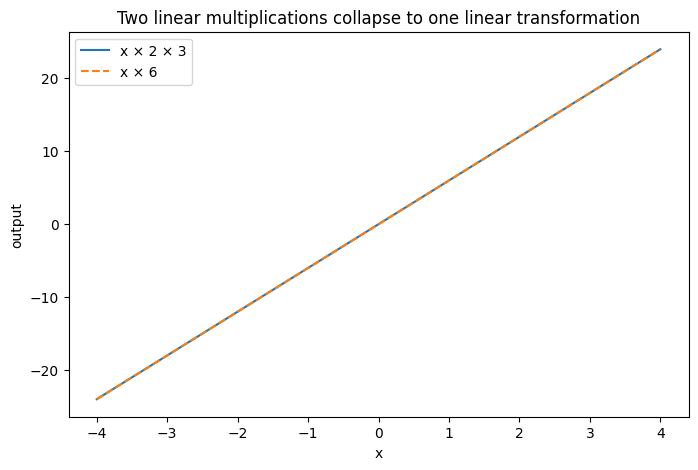

Maximum difference between the two outputs: 0.0


In [ ]:
x_line = np.linspace(-4, 4, 200)
chain_output = (x_line * 2) * 3
single_output = x_line * 6

plt.figure(figsize=(8, 5))
plt.plot(x_line, chain_output, label="x × 2 × 3")
plt.plot(x_line, single_output, linestyle="--", label="x × 6")
plt.xlabel("x")
plt.ylabel("output")
plt.title("Two linear multiplications collapse to one linear transformation")
plt.legend()
plt.show()

print("Maximum difference between the two outputs:", np.max(np.abs(chain_output - single_output)))

Neural networks become much more expressive when a nonlinear **activation function** is inserted after weighted sums.

## 8. ReLU

The Rectified Linear Unit is

$$
\mathrm{ReLU}(z)=\max(0,z)
$$

Negative values become zero. Positive values pass through unchanged.

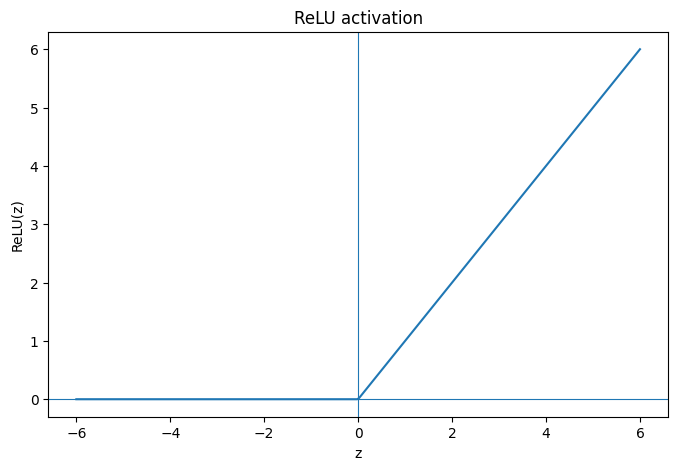

In [ ]:
def relu(z):
    return np.maximum(0, z)

z_values = np.linspace(-6, 6, 300)

plt.figure(figsize=(8, 5))
plt.plot(z_values, relu(z_values))
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.xlabel("z")
plt.ylabel("ReLU(z)")
plt.title("ReLU activation")
plt.show()

## 9. Sigmoid

The sigmoid function is

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

It maps real-valued inputs to values between 0 and 1. This makes it useful when an output is interpreted as a probability in a binary classification setting.

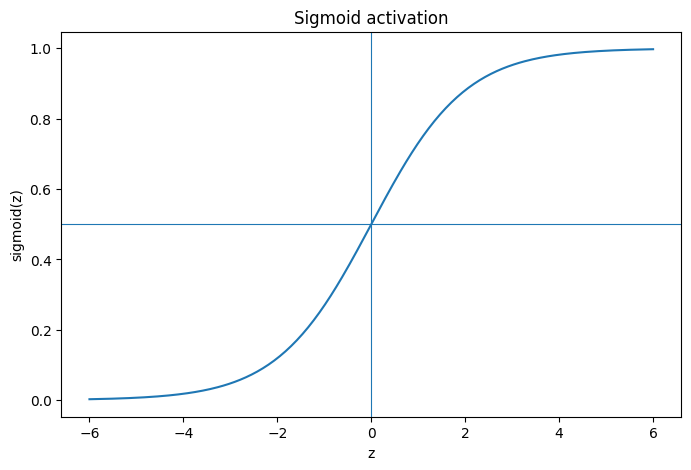

In [ ]:
def sigmoid(z):
    z = np.asarray(z)
    return 1 / (1 + np.exp(-z))

plt.figure(figsize=(8, 5))
plt.plot(z_values, sigmoid(z_values))
plt.axhline(0.5, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.xlabel("z")
plt.ylabel("sigmoid(z)")
plt.title("Sigmoid activation")
plt.show()

## 10. Compare activation outputs

Run the next cell and inspect how the same input values are transformed.

In [ ]:
activation_demo = pd.DataFrame({
    "z": [-4, -1, 0, 1, 4]
})
activation_demo["no_activation"] = activation_demo["z"]
activation_demo["ReLU"] = relu(activation_demo["z"].to_numpy())
activation_demo["sigmoid"] = sigmoid(activation_demo["z"].to_numpy())

display(activation_demo)

,z,no_activation,ReLU,sigmoid
0,-4,-4,0,0.017986
1,-1,-1,0,0.268941
2,0,0,0,0.500000
3,1,1,1,0.731059
4,4,4,4,0.982014


### Main point

Activation is not added merely to make a diagram look more complicated. It changes what the network can represent. With nonlinear activations, layers can combine to model curved and more complex relationships.

# Part E: From one neuron to a layer

## 11. A layer is several neurons working in parallel

Different neurons can receive the same inputs but use different weights and biases. Each neuron therefore creates a different learned combination of the inputs.

We can write a complete layer compactly as:

$$
\mathbf{z}=\mathbf{W}\mathbf{x}+\mathbf{b}
$$

and then apply an activation:

$$
\mathbf{a}=f(\mathbf{z})
$$

In [ ]:
x_vec = np.array([2.0, 3.0, 1.0])

W = np.array([
    [0.5,  0.2, -0.4],
    [0.1, -0.3,  0.8],
    [0.7,  0.4,  0.2]
])

b_vec = np.array([0.1, -0.2, 0.0])

z_layer = W @ x_vec + b_vec
a_layer = relu(z_layer)

print("Input vector x:", x_vec)
print("Weight matrix W:")
print(W)
print("Bias vector b:", b_vec)
print("Weighted sums z:", z_layer)
print("Activations a:", a_layer)


Input vector x: [2. 3. 1.]
Weight matrix W:
[[ 0.5  0.2 -0.4]
 [ 0.1 -0.3  0.8]
 [ 0.7  0.4  0.2]]
Bias vector b: [ 0.1 -0.2  0. ]
Weighted sums z: [ 1.3 -0.1  2.8]
Activations a: [1.3 0.  2.8]


The three neurons produced different internal values because they used different parameter values.

## 12. Input, hidden and output layers

A feed-forward network is often described using three roles:

- **Input layer:** receives the feature values.
- **Hidden layer(s):** creates internal transformations of those features.
- **Output layer:** produces the model's prediction.

"Hidden" means internal to the model. It does not mean that each hidden neuron must correspond to a simple human concept.

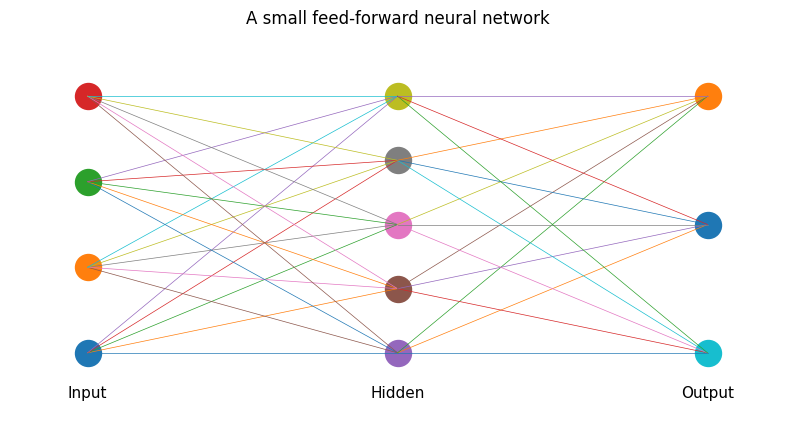

In [ ]:
def draw_network(layer_sizes, title):
    plt.figure(figsize=(10, 5))
    ax = plt.gca()
    ax.axis("off")

    x_positions = np.linspace(1, 9, len(layer_sizes))
    layer_points = []
    for x_pos, size in zip(x_positions, layer_sizes):
        ys = np.linspace(1, 5, size) if size > 1 else np.array([3.0])
        pts = [(x_pos, y) for y in ys]
        layer_points.append(pts)
        for x, y in pts:
            ax.scatter([x], [y], s=350)

    for left, right in zip(layer_points[:-1], layer_points[1:]):
        for x1, y1 in left:
            for x2, y2 in right:
                ax.plot([x1, x2], [y1, y2], linewidth=0.5)

    names = ["Input"] + ["Hidden"] * (len(layer_sizes)-2) + ["Output"]
    for x, name in zip(x_positions, names):
        ax.text(x, 0.3, name, ha="center", fontsize=11)

    ax.set_xlim(0, 10)
    ax.set_ylim(0, 6)
    plt.title(title)
    plt.show()


draw_network([4, 5, 3], "A small feed-forward neural network")

# Part F: Forward propagation

## 13. A prediction moves forward through the network

A **forward pass** uses the current parameter values to calculate a prediction. It does not update the parameters.

We will manually calculate a network with:

- 2 inputs;
- 2 hidden neurons using ReLU;
- 1 output neuron using sigmoid.

In [ ]:
# One input example
x = np.array([1.5, -0.5])

# Hidden layer parameters: 2 hidden neurons × 2 inputs
W1 = np.array([
    [0.8, -0.4],
    [0.3,  0.9]
])
b1 = np.array([0.1, -0.2])

# Output layer parameters: 1 output × 2 hidden neurons
W2 = np.array([[1.1, -0.7]])
b2 = np.array([0.05])

# Hidden layer
z1 = W1 @ x + b1
a1 = relu(z1)

# Output layer
z2 = W2 @ a1 + b2
y_hat = sigmoid(z2)

print("Input x:", x)
print("Hidden weighted sums z1:", z1)
print("Hidden activations a1:", a1)
print("Output weighted sum z2:", z2)
print("Prediction y_hat:", y_hat)

Input x: [ 1.5 -0.5]
Hidden weighted sums z1: [ 1.5 -0.2]
Hidden activations a1: [1.5 0. ]
Output weighted sum z2: [1.7]
Prediction y_hat: [0.84553473]


The calculation followed this sequence:

$$
\mathbf{z}^{(1)}=\mathbf{W}^{(1)}\mathbf{x}+\mathbf{b}^{(1)}
$$

$$
\mathbf{a}^{(1)}=\mathrm{ReLU}(\mathbf{z}^{(1)})
$$

$$
z^{(2)}=\mathbf{W}^{(2)}\mathbf{a}^{(1)}+b^{(2)}
$$

$$
\hat y=\sigma(z^{(2)})
$$

The important distinction is:

> **Forward propagation makes a prediction. It does not by itself mean that learning has happened.**

# Part G: From prediction to loss

## 14. The model needs a numerical error signal

Suppose the network predicts

$$
\hat y=0.30
$$

but the known class label is

$$
y=1.
$$

The training process needs a number that represents how poor that prediction is. This number is called the **loss**.

For binary classification, one common loss is binary cross-entropy:

$$
L=-\left[y\log(\hat y)+(1-y)\log(1-\hat y)\right].
$$

You do not need to derive this formula here. Focus on its role: better predictions should normally produce smaller loss, while confidently wrong predictions should produce larger loss.

In [ ]:
def binary_cross_entropy(y_true, y_prob, eps=1e-12):
    y_prob = np.clip(y_prob, eps, 1 - eps)
    return -(y_true*np.log(y_prob) + (1-y_true)*np.log(1-y_prob))

examples = pd.DataFrame({
    "true_label": [1, 1, 1, 0, 0, 0],
    "predicted_probability_of_1": [0.95, 0.60, 0.10, 0.05, 0.40, 0.90]
})
examples["loss"] = [
    binary_cross_entropy(y, p)
    for y, p in zip(examples["true_label"], examples["predicted_probability_of_1"])
]

display(examples)

,true_label,predicted_probability_of_1,loss
0,1,0.95,0.051293
1,1,0.60,0.510826
2,1,0.10,2.302585
3,0,0.05,0.051293
4,0,0.40,0.510826
5,0,0.90,2.302585


## 15. Loss is not the same as accuracy

**Loss** is detailed numerical feedback used during optimisation.

**Accuracy** is an evaluation metric that asks what fraction of class predictions were correct.

A model may reduce its loss even when the number of correctly classified examples has not yet changed, because its probabilities can become better calibrated or more confident in the correct direction.

# Part H: How learning happens

## 16. The training loop

Training repeatedly performs the same basic cycle:

**forward pass -> calculate loss -> backpropagation -> update parameters -> repeat**

The parameters being updated are principally the weights and biases.

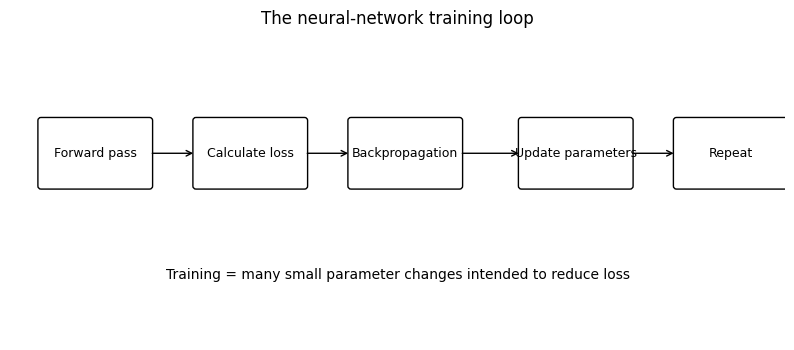

In [ ]:
plt.figure(figsize=(10, 4))
ax = plt.gca()
ax.axis("off")
ax.set_xlim(0, 10)
ax.set_ylim(0, 4)

steps = [
    (0.4, 2.0, "Forward pass"),
    (2.4, 2.0, "Calculate loss"),
    (4.4, 2.0, "Backpropagation"),
    (6.6, 2.0, "Update parameters"),
    (8.6, 2.0, "Repeat")
]
for x0, y0, label in steps:
    box = FancyBboxPatch((x0, y0), 1.4, 0.85, boxstyle="round,pad=0.04", fill=False)
    ax.add_patch(box)
    ax.text(x0+0.7, y0+0.425, label, ha="center", va="center", fontsize=9)
for x1, x2 in [(1.8,2.4),(3.8,4.4),(5.8,6.6),(8.0,8.6)]:
    ax.annotate("", xy=(x2,2.425), xytext=(x1,2.425), arrowprops=dict(arrowstyle="->"))
ax.text(5.0, 0.8, "Training = many small parameter changes intended to reduce loss", ha="center")
plt.title("The neural-network training loop")
plt.show()


## 17. Backpropagation, without the calculus

Backpropagation uses the loss to work out how changes in each parameter relate to the error. In a full deep-learning course, this is developed using derivatives and the chain rule.

For this lesson, the important conceptual statement is:

> Backpropagation supplies the gradient information that an optimiser uses to adjust the network's parameters.

Backpropagation does not make a network "understand" the task like a person. It is a mathematical procedure for assigning useful parameter-update information through the network.

## 18. The optimiser updates parameters

A generic gradient-based parameter update can be written as

$$
\theta_{\text{new}}
=
\theta_{\text{old}}
-
\eta\nabla_{\theta}L
$$

where:

- $\theta$ represents model parameters such as weights and biases;
- $L$ is the loss;
- $\nabla_{\theta}L$ contains gradient information;
- $\eta$ is the learning rate.

The learning rate controls the size of each correction.

# Part I: Learning rate

## 19. Too small, useful, or too large

The learning rate controls the size of a parameter update. We will first use a tiny optimisation problem where the effect is guaranteed to be visible, then train the same neural network with several learning rates.

For the toy problem, suppose the loss is

$$
L(w)=(w-3)^2.
$$

The minimum occurs at $w=3$. Gradient descent repeatedly moves $w$ using the slope of this loss. The purpose is only to visualise update size; the same principle is used when neural-network parameters are updated.


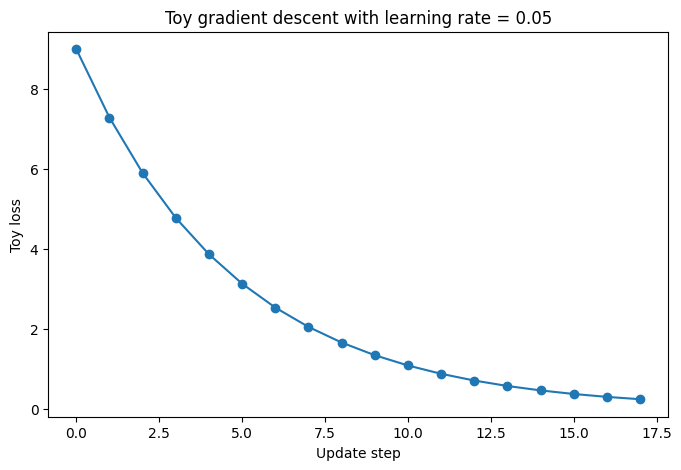

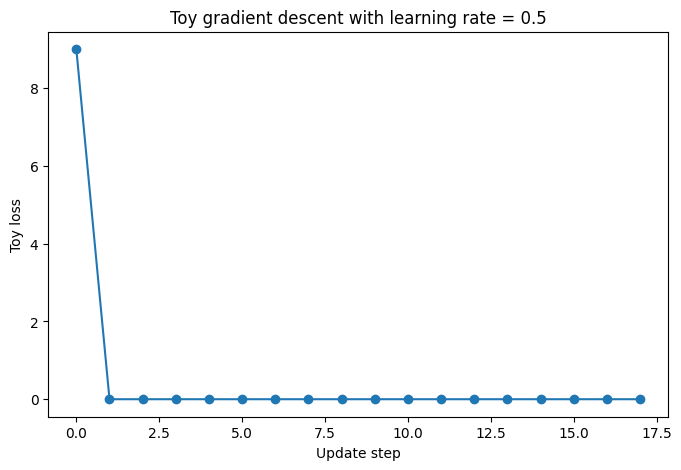

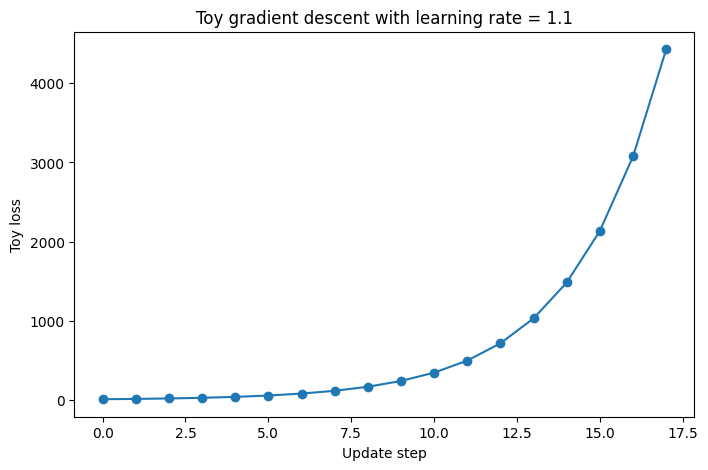

Final values:
lr=0.05: w=2.4997, loss=0.2503
lr=0.5: w=3.0000, loss=0.0000
lr=1.1: w=69.5583, loss=4430.0117


In [ ]:
def toy_gradient_descent(learning_rate, steps=18, start=0.0):
    w = start
    history = []
    for step in range(steps):
        loss = (w - 3.0)**2
        history.append((step, w, loss))
        gradient = 2 * (w - 3.0)
        w = w - learning_rate * gradient
    return pd.DataFrame(history, columns=["step", "w", "loss"])

toy_rates = [0.05, 0.5, 1.1]
toy_histories = {lr: toy_gradient_descent(lr) for lr in toy_rates}

for lr in toy_rates:
    hist = toy_histories[lr]
    plt.figure(figsize=(8, 5))
    plt.plot(hist["step"], hist["loss"], marker="o")
    plt.xlabel("Update step")
    plt.ylabel("Toy loss")
    plt.title(f"Toy gradient descent with learning rate = {lr}")
    plt.show()

print("Final values:")
for lr in toy_rates:
    last = toy_histories[lr].iloc[-1]
    print(f"lr={lr}: w={last['w']:.4f}, loss={last['loss']:.4f}")

In this toy example:

- a small learning rate moves toward the minimum slowly;
- a suitable rate reaches the minimum quickly;
- a rate that is too large overshoots so strongly that the loss grows instead of shrinking.

Real neural-network loss surfaces are much more complicated, but the update-size intuition is the same. We now repeat the idea using an actual MLP.


In [ ]:
learning_rates = [0.0001, 0.01, 0.5]
learning_rate_results = []
learning_rate_models = {}

for lr in learning_rates:
    model = MLPClassifier(
        hidden_layer_sizes=(16,),
        activation="relu",
        solver="sgd",
        momentum=0.0,
        learning_rate_init=lr,
        max_iter=150,
        tol=0,
        n_iter_no_change=1000,
        random_state=RANDOM_STATE
    )
    model.fit(X_train_demo_s, y_train_demo)
    learning_rate_models[lr] = model
    learning_rate_results.append({
        "learning_rate": lr,
        "iterations": model.n_iter_,
        "final_training_loss": model.loss_curve_[-1],
        "train_accuracy": model.score(X_train_demo_s, y_train_demo),
        "test_accuracy": model.score(X_test_demo_s, y_test_demo)
    })

results_lr = pd.DataFrame(learning_rate_results)
display(results_lr)

,learning_rate,iterations,final_training_loss,train_accuracy,test_accuracy
0,0.0001,150,0.680894,0.512000,0.544
1,0.0100,150,0.414916,0.853333,0.856
2,0.5000,150,0.139678,0.954667,0.952


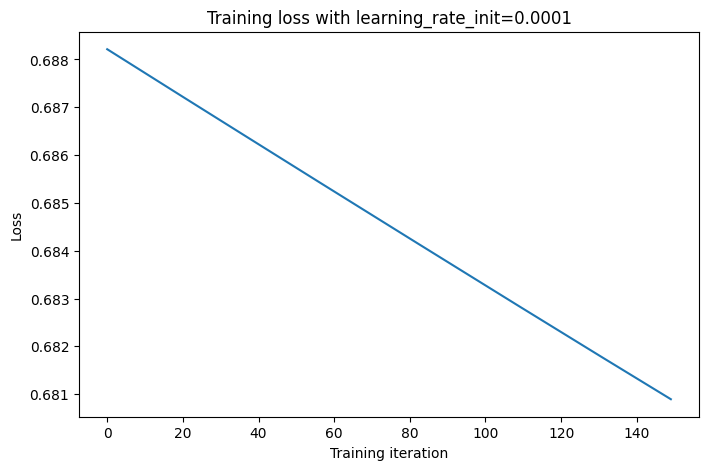

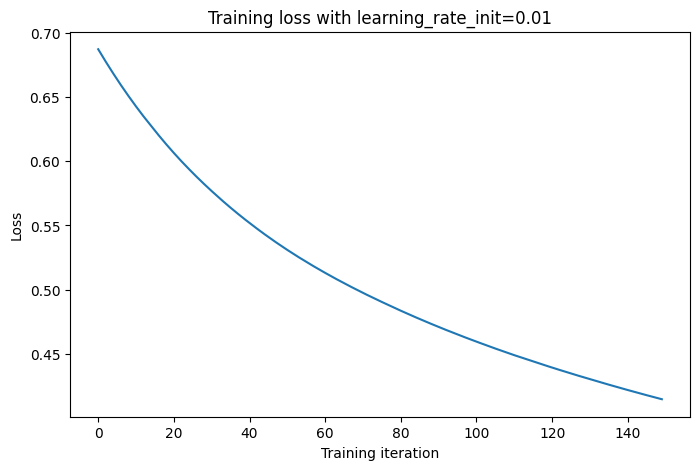

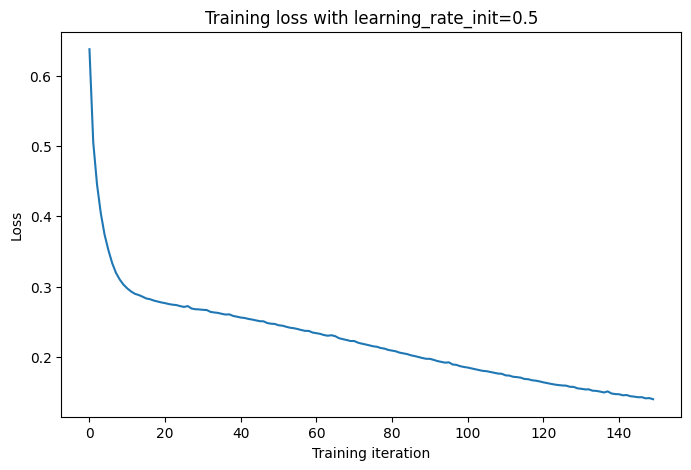

In [ ]:
for lr in learning_rates:
    model = learning_rate_models[lr]
    plt.figure(figsize=(8, 5))
    plt.plot(model.loss_curve_)
    plt.xlabel("Training iteration")
    plt.ylabel("Loss")
    plt.title(f"Training loss with learning_rate_init={lr}")
    plt.show()

### Interpret carefully

The toy optimisation gives the clearest demonstration that an excessively large learning rate can diverge. The MLP experiment shows another important point: the exact useful range depends on the model, data and optimiser. A value that is "large" in one problem may still work in another.

A very small learning rate usually improves slowly. A useful learning rate reduces loss efficiently without unstable updates. The learning rate is a **hyperparameter** chosen by the practitioner rather than learned as an ordinary network weight.


# Part J: Epochs and mini-batches

## 20. One epoch means one full pass through the training set

If a training set contains 100 observations and the batch size is 20, the data can be processed in five mini-batches during one epoch.

An update can occur after each mini-batch, so one epoch may contain several parameter updates.

In [ ]:
n_observations = 100
batch_size = 20
n_batches = int(np.ceil(n_observations / batch_size))

batch_table = pd.DataFrame({
    "batch": np.arange(1, n_batches + 1),
    "start_row": np.arange(0, n_observations, batch_size),
    "end_row_exclusive": np.minimum(np.arange(batch_size, n_observations + batch_size, batch_size), n_observations)
})

display(batch_table)
print("Observations:", n_observations)
print("Batch size:", batch_size)
print("Batches per epoch:", n_batches)

,batch,start_row,end_row_exclusive
0,1,0,20
1,2,20,40
2,3,40,60
3,4,60,80
4,5,80,100


Observations: 100
Batch size: 20
Batches per epoch: 5


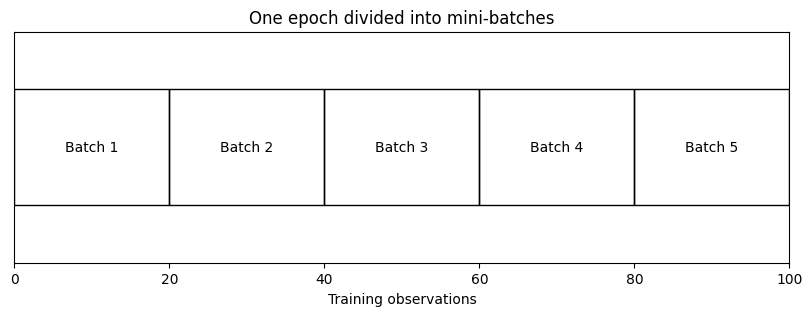

In [ ]:
plt.figure(figsize=(10, 3))
ax = plt.gca()
ax.set_xlim(0, n_observations)
ax.set_ylim(0, 1)
ax.set_yticks([])
ax.set_xlabel("Training observations")
for i in range(n_batches):
    start = i * batch_size
    end = min((i + 1) * batch_size, n_observations)
    ax.add_patch(plt.Rectangle((start, 0.25), end-start, 0.5, fill=False))
    ax.text((start+end)/2, 0.5, f"Batch {i+1}", ha="center", va="center")
plt.title("One epoch divided into mini-batches")
plt.show()

# Part K: Train a small neural network properly

## 21. Create the main nonlinear dataset

We now build a complete small experiment with separate training, validation and test roles.

In [ ]:
X_all, y_all = make_moons(n_samples=900, noise=0.25, random_state=RANDOM_STATE)

# First hold out the final test set.
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X_all, y_all, test_size=0.20, random_state=RANDOM_STATE, stratify=y_all
)

# Then create a validation set from the remaining development data.
X_train, X_valid, y_train, y_valid = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=RANDOM_STATE, stratify=y_trainval
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))
print("Test rows:", len(X_test))

Training rows: 540
Validation rows: 180
Test rows: 180


Scaling is learned from the training data only. The validation and test sets are transformed using those same training-derived statistics.

In [ ]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_valid_s = scaler.transform(X_valid)
X_test_s = scaler.transform(X_test)

print("Scaled training mean, approximately:", np.round(X_train_s.mean(axis=0), 4))
print("Scaled training standard deviation, approximately:", np.round(X_train_s.std(axis=0), 4))

Scaled training mean, approximately: [-0.  0.]
Scaled training standard deviation, approximately: [1. 1.]


## 22. Baseline first: logistic regression

A neural network is not automatically the right model. We first establish a simpler baseline.

In [ ]:
baseline = LogisticRegression(random_state=RANDOM_STATE)
baseline.fit(X_train_s, y_train)

baseline_scores = {
    "train_accuracy": baseline.score(X_train_s, y_train),
    "validation_accuracy": baseline.score(X_valid_s, y_valid),
    "test_accuracy": baseline.score(X_test_s, y_test)
}

print(baseline_scores)

{'train_accuracy': 0.8518518518518519, 'validation_accuracy': 0.8555555555555555, 'test_accuracy': 0.9}


## 23. Train an MLP classifier

`MLP` means **multilayer perceptron**, a feed-forward neural network for vector/tabular inputs.

We will use one hidden layer with 16 neurons.

In [ ]:
net = MLPClassifier(
    hidden_layer_sizes=(16,),
    activation="relu",
    solver="adam",
    learning_rate_init=0.01,
    alpha=0.0001,
    max_iter=500,
    random_state=RANDOM_STATE
)

net.fit(X_train_s, y_train)

print("Training accuracy:", round(net.score(X_train_s, y_train), 3))
print("Validation accuracy:", round(net.score(X_valid_s, y_valid), 3))
print("Test accuracy:", round(net.score(X_test_s, y_test), 3))

Training accuracy: 0.926
Validation accuracy: 0.917
Test accuracy: 0.928


`hidden_layer_sizes=(16,)` means:

- one hidden layer;
- 16 hidden neurons.

A configuration such as `hidden_layer_sizes=(16, 8)` would mean two hidden layers: first 16 neurons, then 8 neurons.

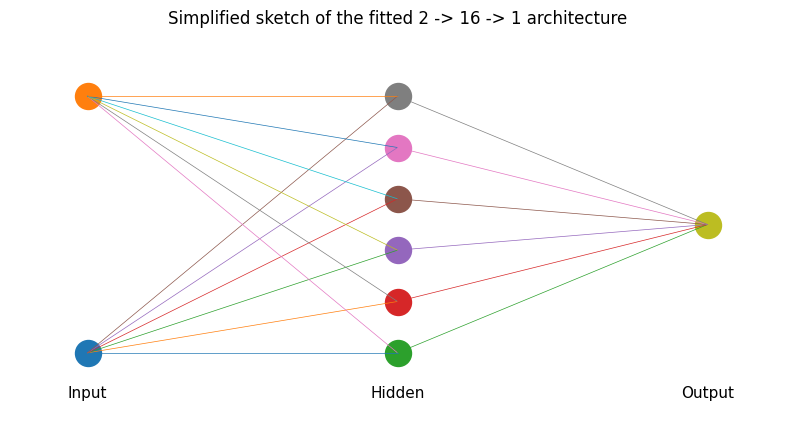

The diagram uses 6 circles for readability; the real hidden layer has 16 neurons.


In [ ]:
draw_network([2, 6, 1], "Simplified sketch of the fitted 2 -> 16 -> 1 architecture")
print("The diagram uses 6 circles for readability; the real hidden layer has 16 neurons.")

# Part L: Look inside the trained network

## 24. Weights and biases are real arrays inside the model

Scikit-learn stores learned weight matrices in `coefs_` and learned bias vectors in `intercepts_`.

In [ ]:
for i, weights in enumerate(net.coefs_):
    print(f"Weight matrix {i}: shape {weights.shape}")
for i, biases in enumerate(net.intercepts_):
    print(f"Bias vector {i}: shape {biases.shape}")

Weight matrix 0: shape (2, 16)
Weight matrix 1: shape (16, 1)
Bias vector 0: shape (16,)
Bias vector 1: shape (1,)


For this network:

- the first weight matrix connects 2 input features to 16 hidden neurons;
- the second weight matrix connects 16 hidden neurons to the output;
- each non-input layer has its own bias values.

This is the practical meaning of the statement that a neural network learns weights and biases.

In [ ]:
print("First five rows of the input-to-hidden weight matrix:")
display(pd.DataFrame(net.coefs_[0]).head())

print("First ten hidden-layer bias values:")
print(np.round(net.intercepts_[0][:10], 4))

First five rows of the input-to-hidden weight matrix:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,3.518219e-21,1.381070,0.156623,-0.035401,-0.159198,0.377830,-2.016181,1.833218,-4.187583e-21,-0.257571,-1.959674,1.677525,2.877486,-1.563941,-0.141861,-2.458044
1,-4.170375e-21,0.314186,-0.161785,-0.103511,-0.068232,-1.231848,-0.930704,-0.124713,-4.081505e-21,2.042423,-0.041121,0.314406,0.161325,-0.952792,-0.066660,-0.103789


First ten hidden-layer bias values:
[-0.5022  0.9584  0.761   0.7575 -0.4513 -1.2461  1.4951 -0.5116 -0.4364
 -0.548 ]


# Part M: Learning curves

## 25. Training loss should normally fall

`MLPClassifier` records its training loss after each optimisation iteration in `loss_curve_`.

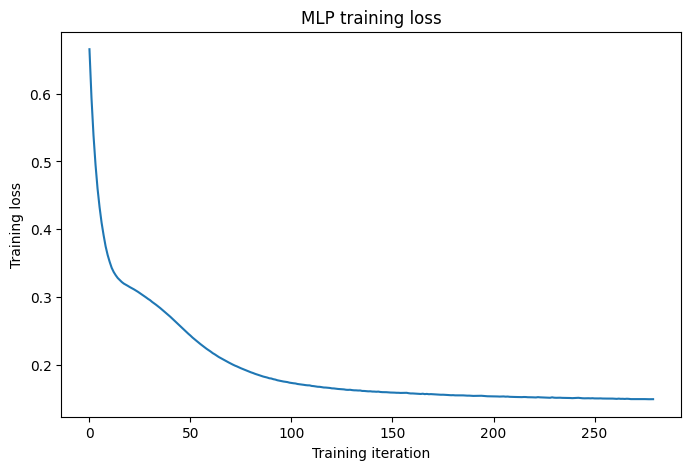

Initial recorded loss: 0.6657
Final recorded loss: 0.1491


In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(net.loss_curve_)
plt.xlabel("Training iteration")
plt.ylabel("Training loss")
plt.title("MLP training loss")
plt.show()

print("Initial recorded loss:", round(net.loss_curve_[0], 4))
print("Final recorded loss:", round(net.loss_curve_[-1], 4))

A useful curve often falls rapidly at first and then improves more slowly. A falling training loss is evidence that the optimisation procedure is fitting the training examples.

It is **not**, by itself, evidence that the model generalises well. For that we need unseen data.

## 26. Track training and validation loss across epochs

The next experiment uses `partial_fit` so that we can inspect both training and validation loss after each pass through the training data.

In [ ]:
monitor_net = MLPClassifier(
    hidden_layer_sizes=(20,),
    activation="relu",
    solver="sgd",
    momentum=0.9,
    learning_rate_init=0.03,
    alpha=0.0005,
    random_state=RANDOM_STATE
)

train_losses = []
valid_losses = []
classes = np.array([0, 1])

epochs = 80
for epoch in range(epochs):
    if epoch == 0:
        monitor_net.partial_fit(X_train_s, y_train, classes=classes)
    else:
        monitor_net.partial_fit(X_train_s, y_train)

    train_prob = monitor_net.predict_proba(X_train_s)[:, 1]
    valid_prob = monitor_net.predict_proba(X_valid_s)[:, 1]
    train_losses.append(log_loss(y_train, train_prob))
    valid_losses.append(log_loss(y_valid, valid_prob))

print("Finished", epochs, "epochs.")

Finished 80 epochs.


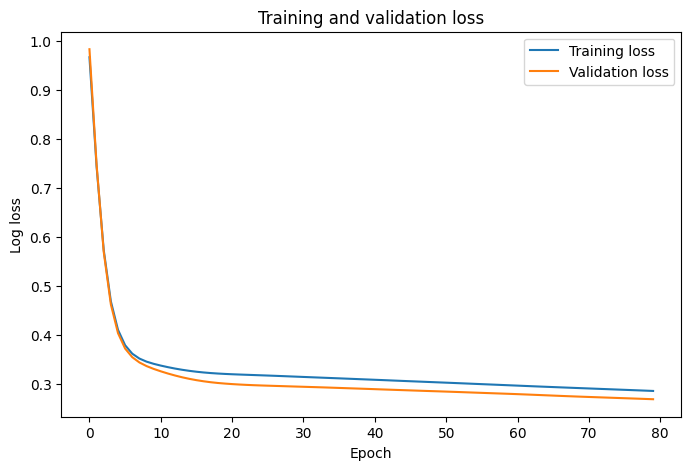

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Training loss")
plt.plot(valid_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Log loss")
plt.title("Training and validation loss")
plt.legend()
plt.show()

### How to read this plot

- Training loss tells us how well the current parameters fit examples used for learning.
- Validation loss tells us how well the current model transfers to held-out development examples.
- If training loss keeps improving while validation loss clearly worsens, that is a warning sign for overfitting.

The exact shape varies from dataset to dataset. Do not expect every healthy model to produce an identical curve.

# Part N: Overfitting

## 27. Deliberately create a harder generalisation problem

To make overfitting easier to observe, we will use a **small, noisy training set**. No labels are deliberately corrupted. The larger network has enough capacity to fit the small training sample extremely closely, while a smaller regularised network is more constrained.


In [ ]:
X_small, y_small = make_moons(n_samples=300, noise=0.30, random_state=7)
X_sm_train, X_sm_test, y_sm_train, y_sm_test = train_test_split(
    X_small, y_small, test_size=0.73, random_state=7, stratify=y_small
)

sm_scaler = StandardScaler()
X_sm_train_s = sm_scaler.fit_transform(X_sm_train)
X_sm_test_s = sm_scaler.transform(X_sm_test)

print("Training rows:", len(X_sm_train_s))
print("Test rows:", len(X_sm_test_s))


Training rows: 81
Test rows: 219


In [ ]:
small_net = MLPClassifier(
    hidden_layer_sizes=(8,),
    alpha=0.02,
    learning_rate_init=0.01,
    max_iter=1000,
    random_state=RANDOM_STATE
)

large_net = MLPClassifier(
    hidden_layer_sizes=(100, 100),
    alpha=1e-8,
    learning_rate_init=0.01,
    max_iter=2500,
    random_state=RANDOM_STATE
)

small_net.fit(X_sm_train_s, y_sm_train)
large_net.fit(X_sm_train_s, y_sm_train)

comparison = pd.DataFrame({
    "model": ["Smaller / more regularised", "Larger / very weak regularisation"],
    "train_accuracy": [
        small_net.score(X_sm_train_s, y_sm_train),
        large_net.score(X_sm_train_s, y_sm_train)
    ],
    "test_accuracy": [
        small_net.score(X_sm_test_s, y_sm_test),
        large_net.score(X_sm_test_s, y_sm_test)
    ]
})
comparison["train_test_gap"] = comparison["train_accuracy"] - comparison["test_accuracy"]
display(comparison)


,model,train_accuracy,test_accuracy,train_test_gap
0,Smaller / more regularised,0.950617,0.917808,0.032809
1,Larger / very weak regularisation,1.000000,0.876712,0.123288


### Interpretation

A large training-to-test gap can indicate that a model is learning training-specific detail instead of patterns that transfer well. In this experiment, compare both the final test performance and the size of the train-test gap.

Do not diagnose overfitting from model size alone. Use evidence such as:

- training versus validation/test performance;
- learning curves;
- behaviour on genuinely new data;
- sensitivity to noise and limited sample size.


# Part O: Training, validation and test roles

## 28. Use the data split language correctly

**Training set**  
Used to fit weights and biases.

**Validation set**  
Used during development to compare settings such as hidden-layer size, learning rate or regularisation.

**Test set**  
Held back for final evaluation after development choices have been made.

If the test set is repeatedly used to choose the architecture, it has effectively become part of model development and is no longer a clean final test.

# Part P: What makes deep learning "deep"?

## 29. Depth means multiple learned layers

"Deep" does not mean conscious, human-like or automatically superior. It refers to networks containing multiple learned transformations between the input and output.

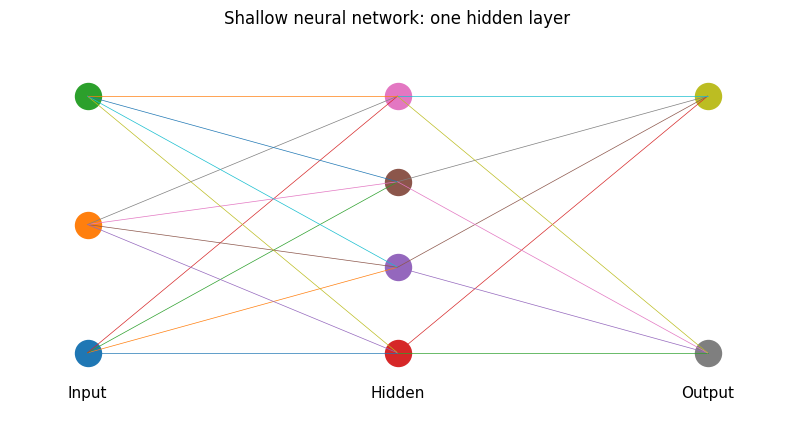

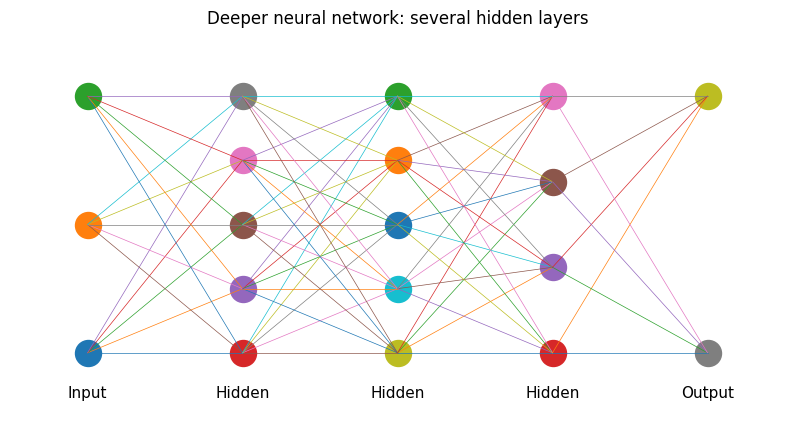

In [ ]:
draw_network([3, 4, 2], "Shallow neural network: one hidden layer")
draw_network([3, 5, 5, 4, 2], "Deeper neural network: several hidden layers")

## 30. Deeper layers can build on earlier representations

A useful intuition for image data is:

**raw pixels -> simple local patterns -> combinations of patterns -> task prediction**

This is not a guarantee that every individual neuron has a clean verbal interpretation. It is a way to understand why successive learned transformations can be useful.

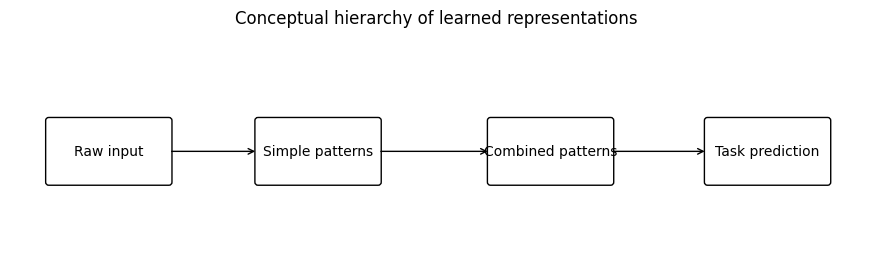

In [ ]:
plt.figure(figsize=(11, 3))
ax = plt.gca()
ax.axis("off")
ax.set_xlim(0, 11)
ax.set_ylim(0, 3)

labels = ["Raw input", "Simple patterns", "Combined patterns", "Task prediction"]
xs = [0.5, 3.2, 6.2, 9.0]
for x0, label in zip(xs, labels):
    box = FancyBboxPatch((x0, 1.05), 1.55, 0.8, boxstyle="round,pad=0.04", fill=False)
    ax.add_patch(box)
    ax.text(x0+0.775, 1.45, label, ha="center", va="center")
for a, b in zip(xs[:-1], xs[1:]):
    ax.annotate("", xy=(b,1.45), xytext=(a+1.55,1.45), arrowprops=dict(arrowstyle="->"))
plt.title("Conceptual hierarchy of learned representations")
plt.show()

# Part Q: Architecture families to recognise

This section is orientation only. The internal mathematics and full implementations belong in later specialised lessons.

## 31. Convolutional Neural Networks (CNNs)

CNNs are designed to exploit **spatial structure**, especially in images. Learned filters scan local regions and produce feature maps. Deeper layers can combine simpler visual patterns into more task-relevant representations.

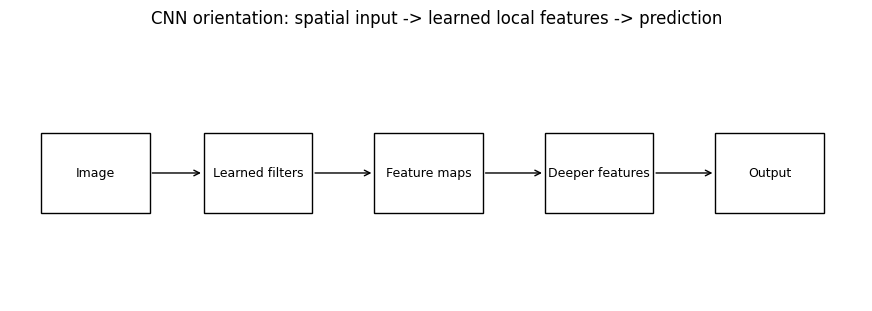

In [ ]:
plt.figure(figsize=(11, 3.5))
ax = plt.gca()
ax.axis("off")
ax.set_xlim(0, 11)
ax.set_ylim(0, 4)

items = [
    (0.4, "Image"),
    (2.5, "Learned filters"),
    (4.7, "Feature maps"),
    (6.9, "Deeper features"),
    (9.1, "Output")
]
for x0, label in items:
    box = plt.Rectangle((x0, 1.3), 1.4, 1.2, fill=False)
    ax.add_patch(box)
    ax.text(x0+0.7, 1.9, label, ha="center", va="center", fontsize=9)
for left, right in zip(items[:-1], items[1:]):
    ax.annotate("", xy=(right[0],1.9), xytext=(left[0]+1.4,1.9), arrowprops=dict(arrowstyle="->"))
plt.title("CNN orientation: spatial input -> learned local features -> prediction")
plt.show()


## 32. Recurrent Neural Networks (RNNs) and LSTMs

RNNs were designed for sequential data. A recurrent hidden state carries information forward through the sequence.

LSTMs are a recurrent architecture designed to control what information is kept, updated or exposed over longer sequences. They were historically important for language, time-series and other sequence tasks.

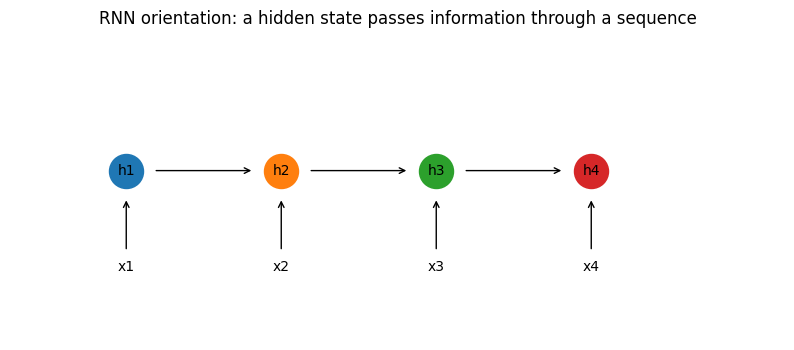

In [ ]:
plt.figure(figsize=(10, 4))
ax = plt.gca()
ax.axis("off")
ax.set_xlim(0, 10)
ax.set_ylim(0, 4)

xs = [1.5, 3.5, 5.5, 7.5]
for i, x0 in enumerate(xs, start=1):
    ax.scatter([x0], [2.2], s=600)
    ax.text(x0, 2.2, f"h{i}", ha="center", va="center")
    ax.text(x0, 0.9, f"x{i}", ha="center")
    ax.annotate("", xy=(x0,1.85), xytext=(x0,1.15), arrowprops=dict(arrowstyle="->"))
for a, b in zip(xs[:-1], xs[1:]):
    ax.annotate("", xy=(b-0.35,2.2), xytext=(a+0.35,2.2), arrowprops=dict(arrowstyle="->"))
plt.title("RNN orientation: a hidden state passes information through a sequence")
plt.show()

## 33. Transformers

Transformers are attention-based neural architectures used broadly in modern AI. Attention allows representations to depend strongly on the most relevant parts of an input sequence rather than only on local recurrence.

At this stage, recognise the family and its central idea. Detailed self-attention mathematics comes later.

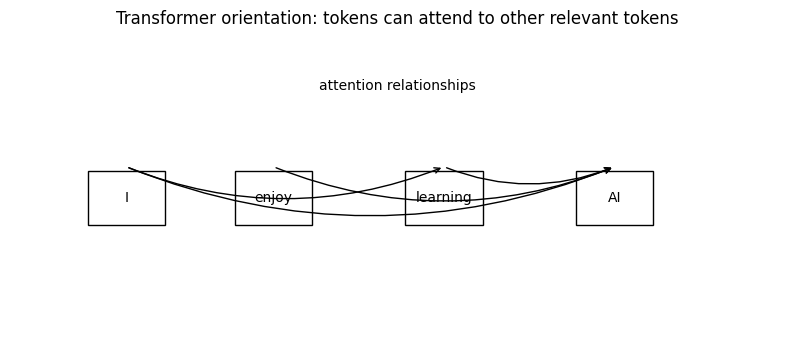

In [ ]:
plt.figure(figsize=(10, 4))
ax = plt.gca()
ax.axis("off")
ax.set_xlim(0, 10)
ax.set_ylim(0, 4)

words = ["I", "enjoy", "learning", "AI"]
xs = [1.5, 3.4, 5.6, 7.8]
for x0, word in zip(xs, words):
    box = plt.Rectangle((x0-0.5, 1.5), 1.0, 0.7, fill=False)
    ax.add_patch(box)
    ax.text(x0, 1.85, word, ha="center", va="center")

# Example attention relationships
for a, b in [(1.5,5.6),(3.4,7.8),(5.6,7.8),(1.5,7.8)]:
    ax.annotate("", xy=(b,2.25), xytext=(a,2.25), arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0.2"))
ax.text(5.0, 3.25, "attention relationships", ha="center")
plt.title("Transformer orientation: tokens can attend to other relevant tokens")
plt.show()

# Part R: Strengths, limitations and model choice

## 34. Neural networks are powerful, but not automatic winners

### Strengths

- can learn nonlinear relationships;
- flexible across many data types;
- can learn useful internal representations;
- can scale to high-dimensional problems.

### Limitations

- can overfit;
- may require substantial data;
- may be harder to interpret;
- computation and tuning matter;
- poor or biased data still produce poor or biased systems.

A sensible principle is:

> Use the simplest model that performs well enough for the real task, unless there is evidence that additional complexity provides a meaningful benefit.

In [ ]:
model_comparison = pd.DataFrame({
    "model": ["Logistic regression baseline", "MLP neural network"],
    "train_accuracy": [baseline.score(X_train_s, y_train), net.score(X_train_s, y_train)],
    "validation_accuracy": [baseline.score(X_valid_s, y_valid), net.score(X_valid_s, y_valid)],
    "test_accuracy": [baseline.score(X_test_s, y_test), net.score(X_test_s, y_test)]
})

display(model_comparison)

,model,train_accuracy,validation_accuracy,test_accuracy
0,Logistic regression baseline,0.851852,0.855556,0.900000
1,MLP neural network,0.925926,0.916667,0.927778


# Part S: A compact reference workflow

## 35. One complete neural-network classification workflow

The next code cell brings the main practical steps together. It is intentionally compact so that you can return to it later as a reference.

In [ ]:
# 1. Create data
X_ref, y_ref = make_moons(n_samples=700, noise=0.25, random_state=123)

# 2. Split
X_ref_train, X_ref_test, y_ref_train, y_ref_test = train_test_split(
    X_ref, y_ref, test_size=0.25, random_state=123, stratify=y_ref
)

# 3. Scale using training data only
ref_scaler = StandardScaler()
X_ref_train_s = ref_scaler.fit_transform(X_ref_train)
X_ref_test_s = ref_scaler.transform(X_ref_test)

# 4. Baseline
ref_baseline = LogisticRegression(random_state=123)
ref_baseline.fit(X_ref_train_s, y_ref_train)

# 5. Neural network
ref_net = MLPClassifier(
    hidden_layer_sizes=(16,),
    activation="relu",
    learning_rate_init=0.01,
    max_iter=500,
    random_state=123
)
ref_net.fit(X_ref_train_s, y_ref_train)

# 6. Evaluate
ref_predictions = ref_net.predict(X_ref_test_s)
print("Baseline test accuracy:", round(ref_baseline.score(X_ref_test_s, y_ref_test), 3))
print("Neural-network test accuracy:", round(accuracy_score(y_ref_test, ref_predictions), 3))
print("Training accuracy:", round(ref_net.score(X_ref_train_s, y_ref_train), 3))

# 7. Inspect mistakes
ref_errors = pd.DataFrame(X_ref_test, columns=["feature_1", "feature_2"])
ref_errors["actual"] = y_ref_test
ref_errors["predicted"] = ref_predictions
ref_errors["correct"] = ref_errors["actual"] == ref_errors["predicted"]

print("Mistakes:", (~ref_errors["correct"]).sum())
display(ref_errors[~ref_errors["correct"]].head(10))

Baseline test accuracy: 0.88
Neural-network test accuracy: 0.926
Training accuracy: 0.95
Mistakes: 13


,feature_1,feature_2,actual,predicted,correct
15,-0.407655,0.655976,1,0,False
16,1.633622,0.214521,0,1,False
37,0.575093,0.238837,1,0,False
52,0.571066,0.159753,1,0,False
63,-0.051846,0.715011,1,0,False
96,0.164875,0.330481,0,1,False
104,0.759445,-0.074037,0,1,False
119,-0.140287,0.759316,1,0,False
124,1.451137,0.387688,0,1,False
128,0.746987,-0.271893,0,1,False


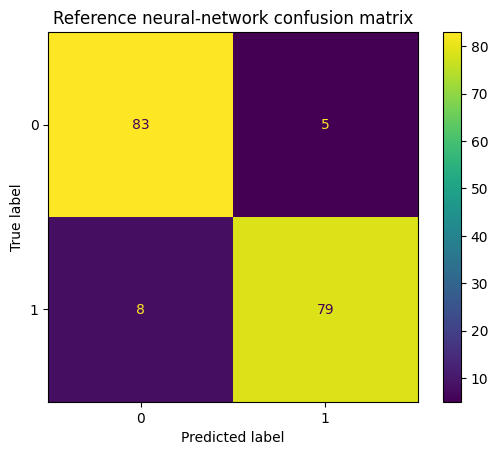

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_ref_test, ref_predictions)
plt.title("Reference neural-network confusion matrix")
plt.show()

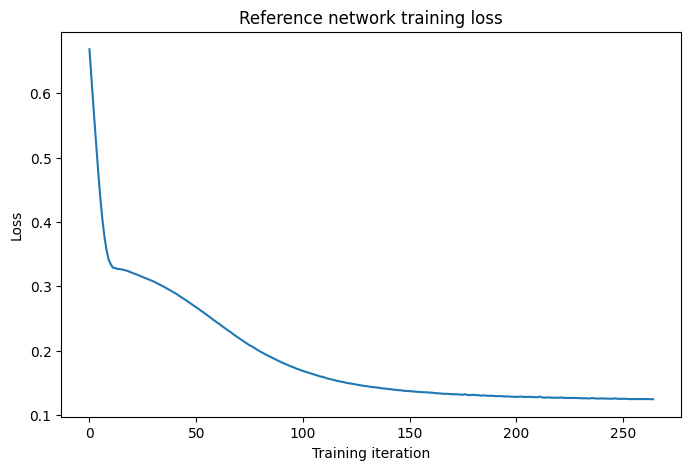

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(ref_net.loss_curve_)
plt.xlabel("Training iteration")
plt.ylabel("Loss")
plt.title("Reference network training loss")
plt.show()

# Part T: Final TODO activities

Complete these four activities yourself. The aim is not merely to make the code run. Record what changed and explain what the result means.

## TODO 1: Build and analyse one neuron

Use:

$$
x_1=3,\qquad x_2=2,\qquad x_3=4
$$

and

$$
w_1=0.6,\qquad w_2=-0.2,\qquad w_3=0.3,\qquad b=-0.1.
$$

### Your tasks

1. Calculate $z$ manually.
2. Implement the weighted sum in Python.
3. Apply ReLU.
4. Apply sigmoid.
5. Change **one** weight and run the calculation again.
6. Explain why the output changed.

In [ ]:
# TODO 1
# x1, x2, x3 = 3, 2, 4
# w1, w2, w3 = 0.6, -0.2, 0.3
# b = -0.1
#
# z_todo1 = ...
# relu_output = ...
# sigmoid_output = ...
#
# print("z =", z_todo1)
# print("ReLU(z) =", relu_output)
# print("sigmoid(z) =", sigmoid_output)

### TODO 1 interpretation

**My manual calculation:**  
...

**What changed when I modified one weight, and why?**  
...

## TODO 2: Investigate learning rate

Train the same MLP three times using:

- `learning_rate_init=0.0001`
- `learning_rate_init=0.01`
- `learning_rate_init=0.5`

Keep the dataset, architecture, solver, random state and number of iterations the same.

### Your tasks

1. Plot the loss curve for each run.
2. Record final training and test accuracy.
3. Identify which run was slow, useful or unstable/poor.
4. Explain why changing several hyperparameters at the same time would weaken your conclusion.

In [ ]:
# TODO 2
# suggested_rates = [0.0001, 0.01, 0.5]
#
# for lr in suggested_rates:
#     todo_model = MLPClassifier(
#         hidden_layer_sizes=(16,),
#         activation="relu",
#         solver="sgd",
#         momentum=0.0,
#         learning_rate_init=lr,
#         max_iter=150,
#         random_state=RANDOM_STATE
#     )
#     # TODO: fit using X_train_demo_s and y_train_demo
#     # TODO: print train and test accuracy
#     # TODO: plot todo_model.loss_curve_

### TODO 2 interpretation

**Which learning rate would I choose from this experiment? Why?**  
...

## TODO 3: Diagnose and reduce overfitting

Use `X_sm_train_s`, `y_sm_train`, `X_sm_test_s`, and `y_sm_test` from the small-sample overfitting experiment.

Start from the larger model. Then change one or two of the following:

- hidden-layer size;
- number of hidden layers;
- regularisation parameter `alpha`;
- training duration.

### Your tasks

1. Record the original training and test accuracy.
2. Explain the evidence for possible overfitting.
3. Modify the model.
4. Retrain using the same data.
5. Record the new training and test accuracy.
6. Decide whether generalisation improved.

In [ ]:
# TODO 3
# original_train = large_net.score(X_sm_train_s, y_sm_train)
# original_test = large_net.score(X_sm_test_s, y_sm_test)
# print("Original train:", original_train)
# print("Original test:", original_test)
#
# improved_net = MLPClassifier(
#     hidden_layer_sizes=(...),
#     alpha=...,
#     learning_rate_init=0.01,
#     max_iter=...,
#     random_state=RANDOM_STATE
# )
#
# TODO: fit improved_net
# TODO: calculate new train and test scores

### TODO 3 interpretation

**Evidence for overfitting:**  
...

**What I changed:**  
...

**Did generalisation improve? Explain using evidence.**  
...

## TODO 4: Is the neural network justified?

Consider the following development results.

| Model | Train accuracy | Test accuracy | Relative training cost | Interpretability |
|---|---:|---:|---|---|
| Logistic regression | 0.89 | 0.88 | Very low | High |
| MLP A | 0.93 | 0.91 | Moderate | Lower |
| MLP B | 1.00 | 0.84 | High | Lower |

### Your tasks

Answer in complete sentences.

1. Which model appears to generalise best?
2. Which model shows the clearest evidence of overfitting?
3. Does the neural-network improvement appear large enough to justify additional complexity? State your assumptions.
4. What additional evidence would you request before deployment?
5. If interpretability were essential, how might your choice change?
6. Give a final model recommendation and justify it.

### TODO 4 answer

**My recommendation:**  
...

**Reasoning:**  
...

# Final recap

The foundation of neural-network learning can be summarised as:

$$
\text{Inputs}
\rightarrow
\text{Weighted sums}
\rightarrow
\text{Activations}
\rightarrow
\hat y
\rightarrow
\text{Loss}
\rightarrow
\text{Backpropagation}
\rightarrow
\text{Parameter updates}
\rightarrow
\text{Repeat}
$$

Before leaving the notebook, make sure you can answer these without looking back:

1. What does one artificial neuron calculate?
2. What does a weight do?
3. What does bias do?
4. Why is an activation function needed?
5. What is a hidden layer?
6. What does forward propagation do?
7. What does loss measure?
8. What does backpropagation accomplish?
9. What actually changes during training?
10. What evidence suggests possible overfitting?
11. What is the role of the validation set?
12. What makes deep learning "deep"?
13. Why is a neural network not automatically better than a simpler baseline?